# Experimento 2x2: ontologia contra documentos

Este notebook lê só o que está publicado em `evaluation/experimento/` e refaz, com as mesmas funções do resumo (`experimento/estatistica.py`), os números da página [`docs/experimento.md`](../docs/experimento.md). Ele não precisa do Ollama nem da pasta `data/`.

O experimento compara quatro condições de contexto para um modelo local que responde perguntas sobre o crédito do SCR.data escrevendo SQL:

- **A:** só o esquema estrela;
- **B:** o esquema mais a ontologia;
- **C:** o esquema mais trechos de documentos do Banco Central, recuperados por busca (RAG);
- **D:** as duas coisas.

São 41 perguntas, dois modelos (Gemma 4 12B e Qwen 3.5 9B) e 5 execuções por pergunta. Uma pergunta acerta quando 3 ou mais das 5 execuções acertam.

- **Execução 1:** falhou no controle de qualidade do instrumento. O Ollama gerava as chaves do JSON em ordem alfabética, e o modelo se abstinha antes de pensar no SQL.
- **Execução 2:** usa o instrumento consertado, a variação V4 ([ADR 0032](../docs/adr/0032-emenda-do-instrumento-do-experimento.md)), e fica no piso: os modelos acertam de 0 a 3 das 41 perguntas em qualquer condição.
- **Execução 3:** usa a variação V6, com o esquema descrito nas quatro condições e, em B e D, só os 5 itens da ontologia mais próximos da pergunta ([ADR 0033](../docs/adr/0033-correcao-do-instrumento-do-experimento.md)). É a confirmatória.

In [1]:
# PT: o publicado e a estatística do projeto, sem dado bruto.
# EN: published results and the project's statistics, no raw data.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

RAIZ = Path.cwd().parent if (Path.cwd().parent / "evaluation").exists() else Path.cwd()
sys.path.insert(0, str(RAIZ))
from experimento import estatistica  # noqa: E402
from experimento.execucoes import EXECUCOES  # noqa: E402

# PT: as execuções publicadas, pelo mapa do experimento/execucoes.py, como
#     na página; a confirmatória é a mais nova.
# EN: published runs, from the experiment's run map; the newest is
#     confirmatory.
PUBLICADO = RAIZ / "evaluation" / "experimento"
resultados = {n: json.loads((PUBLICADO / f"execucao-{n}" / "resultado.json").read_text(encoding="utf-8"))
              for n in EXECUCOES if (PUBLICADO / f"execucao-{n}" / "resultado.json").exists()}
CONFIRMATORIA = max(resultados)
MODELOS = {"gemma-4-12b": "Gemma 4 12B", "qwen3.5-9b": "Qwen 3.5 9B"}
CONDICOES = ["A", "B", "C", "D"]
NOMES = {"A": "A: esquema", "B": "B: ontologia", "C": "C: documentos", "D": "D: as duas"}

# PT: paleta categórica validada (dataviz): o modelo é a identidade.
# EN: validated categorical palette; the model is the identity.
COR = {"gemma-4-12b": "#2a78d6", "qwen3.5-9b": "#eb6834"}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "text.color": "#0b0b0b", "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})

## 1. Quantas perguntas cada condição acerta

O gráfico mostra, das 41 perguntas, quantas cada modelo acerta em cada condição, em cada execução. Na execução 1 quase tudo foi abstenção. Na execução 2 o conserto tirou a abstenção do caminho, e o acerto continuou baixo nas quatro condições. Na execução 3 o Gemma sobe para 5 a 8 perguntas por condição, e o Qwen fica de 2 a 3, perto do que tinha na execução 2, de 0 a 3. A comparação entre execuções é descritiva: entre elas mudaram o instrumento e, na 3, a versão do Ollama.

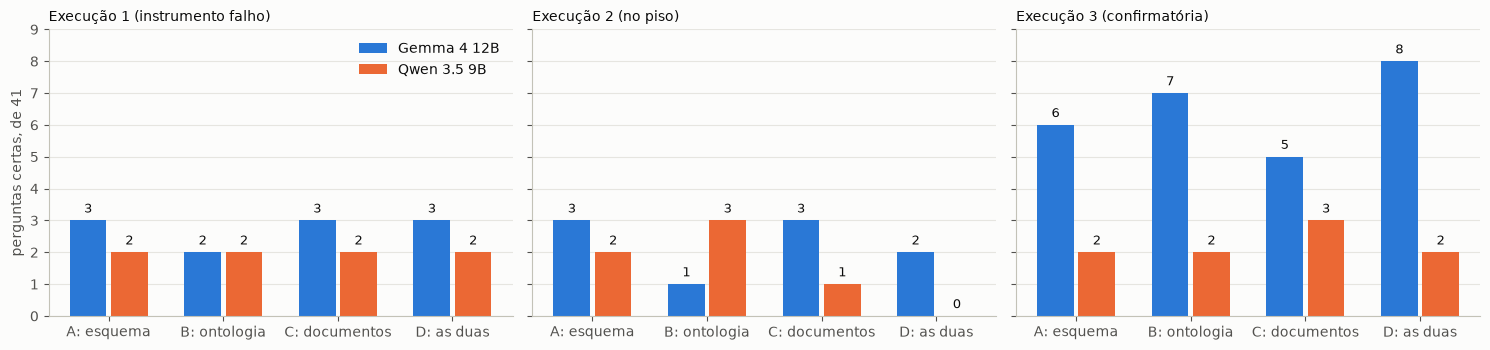

In [2]:
# PT: perguntas certas por condição e modelo, uma faixa por execução.
# EN: right questions per condition and model, one panel per run.
# PT: squeeze=False devolve sempre uma grade, mesmo com uma execução só.
# EN: squeeze=False always returns a grid, even with a single run.
fig, grade = plt.subplots(1, len(resultados), figsize=(5 * len(resultados), 3.6), sharey=True, squeeze=False)
eixos = grade[0]
largura = 0.36
for eixo, n in zip(eixos, sorted(resultados)):
    for k, (modelo, nome) in enumerate(MODELOS.items()):
        certas = [resultados[n]["modelos"][modelo]["analise"]["condicoes"][c]["perguntas_certas"] for c in CONDICOES]
        xs = [i + (k - 0.5) * largura for i in range(4)]
        barras = eixo.bar(xs, certas, width=largura - 0.04, color=COR[modelo], label=nome)
        for x, v in zip(xs, certas):
            eixo.text(x, v + 0.15, str(v), ha="center", va="bottom", fontsize=9, color="#0b0b0b")
    eixo.set_xticks(range(4), [NOMES[c] for c in CONDICOES])
    situacao = "instrumento falho" if n == 1 else "confirmatória" if n == CONFIRMATORIA else "no piso"
    eixo.set_title(f"Execução {n} ({situacao})", loc="left", fontsize=10, color="#0b0b0b")
    eixo.yaxis.grid(True, color="#e6e5e0", linewidth=0.8)
    eixo.set_axisbelow(True)
eixos[0].set_ylabel("perguntas certas, de 41")
maximo = max(r["modelos"][m]["analise"]["condicoes"][c]["perguntas_certas"]
             for r in resultados.values() for m in MODELOS for c in CONDICOES)
eixos[0].set_ylim(0, max(6, maximo + 1))
# PT: a legenda vai no painel de barras mais baixas, para não cobrir um rótulo.
# EN: the legend goes on the lowest-bar panel, so it covers no label.
eixos[0].legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

## 2. O efeito de cada hipótese, com o intervalo

Cada ponto é a diferença pareada de proporções entre duas condições, em pontos percentuais, com o intervalo de Newcombe de 95%. A linha cheia é o zero. Na H4 (D contra B e contra C), a linha tracejada é a margem de não inferioridade de −5 pontos. Na execução 3, todos os intervalos cruzam o zero: nenhuma condição se destaca.

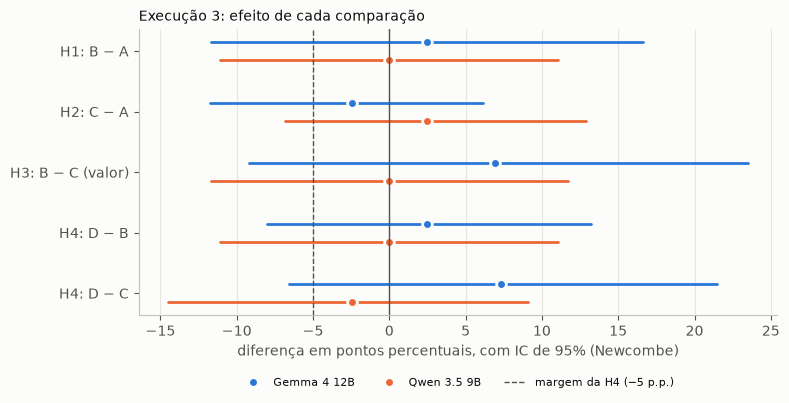

In [3]:
# PT: efeitos da execução confirmatória por hipótese e modelo (floresta).
# EN: confirmatory run effects per hypothesis and model (forest plot).
rotulos, linhas = [], []
for h, texto in (("H1", "H1: B − A"), ("H2", "H2: C − A"), ("H3", "H3: B − C (valor)")):
    rotulos.append(texto)
    linhas.append({m: resultados[CONFIRMATORIA]["modelos"][m]["analise"]["hipoteses"][h] for m in MODELOS})
for chave, texto in (("D−B", "H4: D − B"), ("D−C", "H4: D − C")):
    rotulos.append(texto)
    linhas.append({m: resultados[CONFIRMATORIA]["modelos"][m]["analise"]["hipoteses"]["H4"]["comparacoes"][chave]
                   for m in MODELOS})

fig, eixo = plt.subplots(figsize=(8, 4.2))
for i, linha in enumerate(linhas):
    for k, modelo in enumerate(MODELOS):
        r = linha[modelo]
        y = i + (k - 0.5) * 0.3
        baixo, alto = r["ic95_pp"]
        eixo.plot([baixo, alto], [y, y], color=COR[modelo], linewidth=2, solid_capstyle="round")
        eixo.plot(r["diferenca_pp"], y, "o", color=COR[modelo], markersize=7, markeredgecolor="#fcfcfb",
                  markeredgewidth=2, label=MODELOS[modelo] if i == 0 else None)
eixo.axvline(0, color="#52514e", linewidth=1)
eixo.axvline(-5, color="#52514e", linewidth=1, linestyle="--", label="margem da H4 (−5 p.p.)")
eixo.set_yticks(range(len(rotulos)), rotulos)
eixo.invert_yaxis()
eixo.set_xlabel("diferença em pontos percentuais, com IC de 95% (Newcombe)")
eixo.xaxis.grid(True, color="#e6e5e0", linewidth=0.8)
eixo.set_axisbelow(True)
eixo.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8)
eixo.set_title(f"Execução {CONFIRMATORIA}: efeito de cada comparação", loc="left", fontsize=10)
fig.tight_layout()
plt.show()

## 3. Onde as execuções erram

Das 205 execuções de cada condição (41 perguntas, 5 seeds), o gráfico separa o desfecho na execução confirmatória. O maior grupo é o das respostas com um valor que não bate com o gabarito, de 41% a 52% das execuções de cada condição. Depois vêm as falhas mecânicas (SQL que não roda, guarda, tempo, formato), as abstenções em perguntas que tinham resposta e as respostas que erraram a ressalva ou deixaram de se abster. Quase todo erro de formato é a resposta cortada no limite de 2.048 tokens, a maior parte na segunda chamada, quando o modelo copia para a resposta o resultado inteiro do SQL, como já acontecia na execução 2. A tabela abaixo do gráfico traz os números.

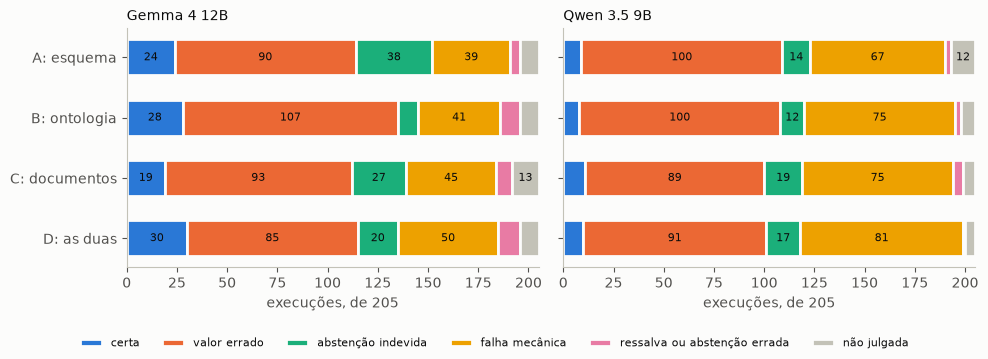

| Modelo | Condição | Certa | Valor errado | Abstenção indevida | Falha mecânica | Ressalva ou abstenção errada | Não julgada |
|---|---|---:|---:|---:|---:|---:|---:|
| Gemma 4 12B | A: esquema | 24 | 90 | 38 | 39 | 5 | 9 |
| Gemma 4 12B | B: ontologia | 28 | 107 | 10 | 41 | 10 | 9 |
| Gemma 4 12B | C: documentos | 19 | 93 | 27 | 45 | 8 | 13 |
| Gemma 4 12B | D: as duas | 30 | 85 | 20 | 50 | 11 | 9 |
| Qwen 3.5 9B | A: esquema | 9 | 100 | 14 | 67 | 3 | 12 |
| Qwen 3.5 9B | B: ontologia | 8 | 100 | 12 | 75 | 3 | 7 |
| Qwen 3.5 9B | C: documentos | 11 | 89 | 19 | 75 | 5 | 6 |
| Qwen 3.5 9B | D: as duas | 10 | 91 | 17 | 81 | 1 | 5 |

In [4]:
# PT: desfecho das execuções na execução confirmatória, por condição e modelo.
# EN: confirmatory run outcomes per condition and model.
# PT: cada motivo de erro do corretor cai num grupo só; um motivo novo para
#     a conta, em vez de sumir do gráfico.
# EN: each grader reason maps to one group; an unknown reason stops.
GRUPOS = {
    "valor errado": ["valor"],
    "abstenção indevida": ["abstencao_indevida"],
    "falha mecânica": ["erro_sql", "erro_guarda", "erro_tempo", "erro_formato", "erro_contexto"],
    "ressalva ou abstenção errada": ["sem_abstencao", "sem_ressalva"],
}
COR_GRUPO = {"certa": "#2a78d6", "valor errado": "#eb6834", "abstenção indevida": "#1baf7a",
             "falha mecânica": "#eda100", "ressalva ou abstenção errada": "#e87ba4", "não julgada": "#c3c2b7"}


def grupo_do_motivo(motivo: str) -> str:
    if motivo.startswith("julgamento_"):
        return "ressalva ou abstenção errada"
    for g, motivos in GRUPOS.items():
        if motivo in motivos:
            return g
    raise ValueError(f"motivo de erro sem grupo: {motivo}")


def desfechos(modelo: str, condicao: str) -> dict[str, int]:
    m = resultados[CONFIRMATORIA]["modelos"][modelo]
    situacoes = [s for por in m["execucoes"][condicao].values() for s in por]
    saida = {g: 0 for g in COR_GRUPO}
    for motivo, n in m["erros_por_motivo"][condicao].items():
        saida[grupo_do_motivo(motivo)] += n
    saida["certa"] = situacoes.count("certo")
    saida["não julgada"] = situacoes.count("pendente")
    assert sum(saida.values()) == len(situacoes), (modelo, condicao, saida)
    return saida


fig, eixos = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
tabela = ["| Modelo | Condição | " + " | ".join(g.capitalize() for g in COR_GRUPO) + " |",
          "|---|---|" + "---:|" * len(COR_GRUPO)]
for eixo, (modelo, nome) in zip(eixos, MODELOS.items()):
    for i, c in enumerate(CONDICOES):
        d = desfechos(modelo, c)
        esquerda = 0
        for g in COR_GRUPO:
            eixo.barh(i, d[g], left=esquerda, color=COR_GRUPO[g], height=0.6, edgecolor="#fcfcfb", linewidth=2,
                      label=g if i == 0 else None)
            if d[g] >= 12:
                eixo.text(esquerda + d[g] / 2, i, str(d[g]), ha="center", va="center", fontsize=8, color="#0b0b0b")
            esquerda += d[g]
        tabela.append(f"| {nome} | {NOMES[c]} | " + " | ".join(str(d[g]) for g in COR_GRUPO) + " |")
    eixo.set_yticks(range(4), [NOMES[c] for c in CONDICOES])
    eixo.set_title(nome, loc="left", fontsize=10)
    eixo.set_xlabel("execuções, de 205")
    eixo.set_xlim(0, 205)
# PT: o eixo y é compartilhado: inverter uma vez põe A em cima nos dois.
# EN: shared y axis: invert once.
eixos[0].invert_yaxis()
fig.legend(*eixos[0].get_legend_handles_labels(), loc="lower center", ncol=6, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()
display(Markdown("\n".join(tabela)))

## 4. Memória de cálculo

O cálculo de cada hipótese refeito passo a passo para o Gemma na execução confirmatória, a partir das perguntas certas por condição publicadas. A notação da tabela pareada é a de Newcombe (1998): `e` as duas condições acertam, `f` só a primeira, `g` só a segunda, `h` nenhuma.

In [5]:
# PT: tabela pareada, McNemar, Newcombe e Holm refeitos e conferidos.
# EN: paired table, McNemar, Newcombe and Holm recomputed and checked.
modelo = "gemma-4-12b"
m = resultados[CONFIRMATORIA]["modelos"][modelo]
certas = m["certas"]
acerta = {c: [certas[c][q] >= 3 for q in certas[c]] for c in CONDICOES}
linhas = ["| Hipótese | e | f | g | h | Diferença (p.p.) | IC 95% (p.p.) | p | Igual ao publicado |",
          "|---|---:|---:|---:|---:|---:|---|---:|---|"]
for h, (primeira, segunda) in (("H1", ("B", "A")), ("H2", ("C", "A"))):
    t = estatistica.tabela_pareada(acerta[primeira], acerta[segunda])
    p = estatistica.mcnemar_exato_unilateral(t.f, t.g)
    baixo, alto = estatistica.newcombe_pareado(t)
    pub = m["analise"]["hipoteses"][h]
    n = t.e + t.f + t.g + t.h
    diferenca = 100 * (t.f - t.g) / n
    igual = (abs(p - pub["p"]) < 1e-6 and abs(diferenca - pub["diferenca_pp"]) < 1e-3
             and abs(100 * baixo - pub["ic95_pp"][0]) < 1e-3 and abs(100 * alto - pub["ic95_pp"][1]) < 1e-3)
    linhas.append(f"| {h} | {t.e} | {t.f} | {t.g} | {t.h} | {diferenca:.1f} | "
                  f"{100 * baixo:.1f} a {100 * alto:.1f} | {p:.3f} | {'sim' if igual else 'NÃO'} |")
display(Markdown("\n".join(linhas)))

passos = m["analise"]["holm"]["passos"]
display(Markdown("**Holm na família H1 a H4:**\n\n| Ordem | Hipótese | p | Multiplicador | p ajustado |\n"
                 "|---:|---|---:|---:|---:|\n" + "\n".join(
                     f"| {i} | {s['hipotese']} | {s['p']:.4f} | {s['multiplicador']} | {s['p_ajustado']:.4f} |"
                     for i, s in enumerate(passos, 1))))

| Hipótese | e | f | g | h | Diferença (p.p.) | IC 95% (p.p.) | p | Igual ao publicado |
|---|---:|---:|---:|---:|---:|---|---:|---|
| H1 | 3 | 4 | 3 | 31 | 2.4 | -11.7 a 16.6 | 0.500 | sim |
| H2 | 5 | 0 | 1 | 35 | -2.4 | -11.8 a 6.2 | 1.000 | sim |

**Holm na família H1 a H4:**

| Ordem | Hipótese | p | Multiplicador | p ajustado |
|---:|---|---:|---:|---:|
| 1 | H4 | 0.0736 | 4 | 0.2944 |
| 2 | H3 | 0.3125 | 3 | 0.9375 |
| 3 | H1 | 0.5000 | 2 | 1.0000 |
| 4 | H2 | 1.0000 | 1 | 1.0000 |

## O que o resultado diz

- **Nenhuma hipótese se sustenta na execução 3, nos dois modelos.** Os intervalos de todas as comparações cruzam o zero.
- **A correção do instrumento ajudou o Gemma, e não o Qwen.** Com o esquema descrito e a ontologia recortada por pergunta, o Gemma passou de 1 a 3 para 5 a 8 perguntas certas por condição, e de 39 para 101 execuções certas, de 820. O Qwen ficou em 2 a 3 perguntas por condição.
- **Ainda há poucos acertos para separar as condições.** Com 5 a 8 perguntas certas, quase não há par discordante, e o efeito mínimo detectável com 41 pares fica entre 25 e 35 pontos (ADR 0032).
- **Sobra um limite mecânico.** De 9% a 12% das execuções terminam com a resposta cortada no limite de tokens, quase sempre na segunda chamada, quando o modelo copia o resultado inteiro do SQL. Ele já existia na execução 2 e fica registrado como limite do instrumento.
- **A leitura honesta** é que, para perguntas analíticas com esse nível de complexidade, o limite continua no modelo de 9 a 12 bilhões de parâmetros, mais que no contexto. Separar o efeito do contexto pediria modelos maiores ou perguntas mais simples. Fica como próximo passo, e não como conclusão.

Os limites declarados estão na página [`docs/experimento.md`](../docs/experimento.md) e nos ADRs 0032 e 0033.